# 03 - Baseline Models: Logistic Regression, KNN, Decision Tree
**Lab link:** Exp 3 (regression -> Logistic Regression), Exp 4/5 (distance measures, KNN), Exp 6 (Decision Tree / ID3 idea)

| Model | Features used | Why |
|-------|---------------|-----|
| Logistic Regression | full hybrid TF-IDF | strong simple baseline for text |
| KNN | 100-dim SVD features | distance-based idea from Exp 4/5 (too slow on 30,000 sparse columns) |
| Decision Tree | 100-dim SVD features | rule-based model from Exp 6 |

**Metrics:** column-averaged ROC-AUC (main) and Macro F1 at threshold 0.5. *No accuracy* because of class imbalance (see EDA).

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, f1_score


def evaluate(y_true, probs):
    """Returns (column-averaged ROC-AUC, macro F1 at 0.5, list of per-label AUCs)."""
    y_true = np.asarray(y_true)
    aucs = []
    for i in range(6):
        if y_true[:, i].sum() == 0:          # label missing in this split -> cannot compute AUC
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, i], probs[:, i]))
    f1 = f1_score(y_true, (probs >= 0.5).astype(int), average="macro", zero_division=0)
    return np.nanmean(aucs), f1, aucs


def to_matrix(proba_list):
    """Tree / KNN models give a list of (n,2) arrays (one per label) -> one (n,6) matrix."""
    return np.column_stack([p[:, 1] if p.shape[1] == 2 else np.zeros(len(p)) for p in proba_list])

import scipy.sparse as sp

X_train = sp.load_npz(PROC / "X_train_tfidf.npz")
X_val = sp.load_npz(PROC / "X_val_tfidf.npz")
y_train = pd.read_csv(PROC / "y_train.csv")[LABELS].values
y_val = pd.read_csv(PROC / "y_val.csv")[LABELS].values
print("TF-IDF train:", X_train.shape, "| validation:", X_val.shape)

X_train_svd = np.load(PROC / "X_train_svd.npy")
X_val_svd = np.load(PROC / "X_val_svd.npy")
results = []      # we will fill this table model by model

TF-IDF train: (127656, 30000) | validation: (31915, 30000)


## 1. Logistic Regression (baseline)

In [2]:
lr = OneVsRestClassifier(LogisticRegression(C=1.0, max_iter=1000))
start = time.time()
lr.fit(X_train, y_train)
lr_time = time.time() - start

lr_probs = lr.predict_proba(X_val)
auc, f1, per_label = evaluate(y_val, lr_probs)
results.append({"Model": "Logistic Regression", "Features": "TF-IDF (30k)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": lr_time})
print(f"Logistic Regression -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f} | {lr_time:.0f} s")
print(dict(zip(LABELS, np.round(per_label, 4))))

Logistic Regression -> ROC-AUC 0.9846 | Macro F1 0.5557 | 74 s
{'toxic': np.float64(0.979), 'severe_toxic': np.float64(0.9876), 'obscene': np.float64(0.9893), 'threat': np.float64(0.982), 'insult': np.float64(0.9831), 'identity_hate': np.float64(0.9869)}


## 2. KNN (distance-based)
KNN on 100,000+ points is slow, so we use a **random subset of 40,000 training comments** to fit and score on 10,000 validation comments. We pick `k` using a separate *dev* set taken from the training data (so the validation set stays untouched). Distance used: Euclidean on the SVD features.

In [3]:
rng = np.random.RandomState(42)
perm = rng.permutation(len(X_train_svd))
fit_size = min(40000, int(0.8 * len(perm)))
fit_idx = perm[:fit_size]                       # KNN "memory"
dev_idx = perm[fit_size: fit_size + 10000]      # dev set (from train) to choose k
val_idx = rng.choice(len(X_val_svd), size=min(10000, len(X_val_svd)), replace=False)

dev_scores = {}
for k in [5, 15, 31]:
    knn = KNeighborsClassifier(n_neighbors=k, algorithm="brute", n_jobs=-1)
    knn.fit(X_train_svd[fit_idx], y_train[fit_idx])
    p = to_matrix(knn.predict_proba(X_train_svd[dev_idx]))
    dev_scores[k] = evaluate(y_train[dev_idx], p)[0]
    print(f"k = {k:2d} -> dev ROC-AUC {dev_scores[k]:.4f}")

best_k = max(dev_scores, key=dev_scores.get)
print("Chosen k:", best_k)

k =  5 -> dev ROC-AUC 0.7987


k = 15 -> dev ROC-AUC 0.8616


k = 31 -> dev ROC-AUC 0.8968
Chosen k: 31


In [4]:
knn = KNeighborsClassifier(n_neighbors=best_k, algorithm="brute", n_jobs=-1)
start = time.time()
knn.fit(X_train_svd[fit_idx], y_train[fit_idx])
knn_time = time.time() - start

knn_probs = to_matrix(knn.predict_proba(X_val_svd[val_idx]))
auc, f1, per_label = evaluate(y_val[val_idx], knn_probs)
results.append({"Model": f"KNN (k={best_k}, 40k subset)", "Features": "SVD (100)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": knn_time})
print(f"KNN -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f}  (scored on {len(val_idx)} validation comments)")
print(dict(zip(LABELS, np.round(per_label, 4))))

KNN -> ROC-AUC 0.8812 | Macro F1 0.3092  (scored on 10000 validation comments)
{'toxic': np.float64(0.8867), 'severe_toxic': np.float64(0.9038), 'obscene': np.float64(0.9207), 'threat': np.float64(0.8041), 'insult': np.float64(0.9151), 'identity_hate': np.float64(0.8566)}


**Note:** KNN "training" is just storing the data - the real cost is at prediction time, which is why we used a subset. Its probabilities are coarse (multiples of 1/k).

## 3. Decision Tree
We check how deep the tree should be: too shallow = underfitting, too deep = overfitting. We test depths on the same 40,000-comment subset and score on the dev set.

max_depth =  4 -> train AUC 0.8831 | dev AUC 0.8758


max_depth =  8 -> train AUC 0.9457 | dev AUC 0.8693


max_depth = 12 -> train AUC 0.9734 | dev AUC 0.8058


max_depth = 16 -> train AUC 0.9784 | dev AUC 0.7901
Chosen max_depth: 4


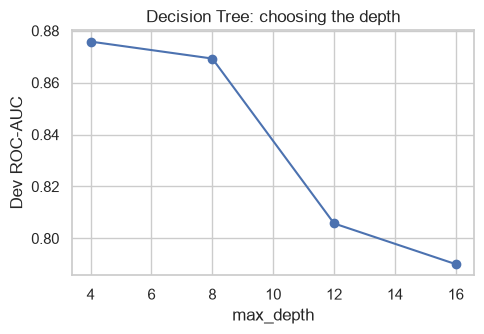

In [5]:
depth_scores = {}
for depth in [4, 8, 12, 16]:
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42)
    dt.fit(X_train_svd[fit_idx], y_train[fit_idx])
    train_auc = evaluate(y_train[fit_idx], to_matrix(dt.predict_proba(X_train_svd[fit_idx])))[0]
    dev_auc = evaluate(y_train[dev_idx], to_matrix(dt.predict_proba(X_train_svd[dev_idx])))[0]
    depth_scores[depth] = dev_auc
    print(f"max_depth = {depth:2d} -> train AUC {train_auc:.4f} | dev AUC {dev_auc:.4f}")

best_depth = max(depth_scores, key=depth_scores.get)
print("Chosen max_depth:", best_depth)

plt.figure(figsize=(5, 3.5))
plt.plot(list(depth_scores.keys()), list(depth_scores.values()), marker="o")
plt.xlabel("max_depth")
plt.ylabel("Dev ROC-AUC")
plt.title("Decision Tree: choosing the depth")
plt.tight_layout()
plt.savefig(ASSETS / "decision_tree_depth.png", dpi=150)
plt.show()

In [6]:
dt = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, random_state=42)
start = time.time()
dt.fit(X_train_svd, y_train)                    # final fit on the full training set
dt_time = time.time() - start

dt_probs = to_matrix(dt.predict_proba(X_val_svd))
auc, f1, per_label = evaluate(y_val, dt_probs)
results.append({"Model": f"Decision Tree (depth={best_depth})", "Features": "SVD (100)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": dt_time})
print(f"Decision Tree -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f} | {dt_time:.0f} s")
print(dict(zip(LABELS, np.round(per_label, 4))))

Decision Tree -> ROC-AUC 0.8715 | Macro F1 0.2224 | 27 s
{'toxic': np.float64(0.8277), 'severe_toxic': np.float64(0.9418), 'obscene': np.float64(0.8764), 'threat': np.float64(0.8774), 'insult': np.float64(0.8758), 'identity_hate': np.float64(0.8295)}


## 4. Baseline summary

In [7]:
baseline_table = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
baseline_table.to_csv(PROC / "results_03.csv", index=False)
baseline_table.round(4)

,Model,Features,ROC-AUC,Macro F1,Train time (s)
0,Logistic Regression,TF-IDF (30k),0.9846,0.5557,74.1290
1,"KNN (k=31, 40k subset)",SVD (100),0.8812,0.3092,0.0653
2,Decision Tree (depth=4),SVD (100),0.8715,0.2224,26.7317


**What to say in the viva:** Logistic Regression on the full TF-IDF is the baseline to beat. KNN and Decision Tree work on only 100 SVD numbers per comment, so they lose a lot of word-level detail. Trees also struggle with rare labels like `threat` because very few examples reach each leaf.

Next: `04_model_comparison.ipynb` adds SVM, Naive Bayes and Random Forest.